# 04 · Baseline model validation (Prompt 7)

GAM and degree-day OLS fitted per BA on the 2016–2019 baseline (COVID excluded), validated by leaving one year out
(one month out for DOM, whose EIA-930 series starts 2018-09). Outputs come from `python -m glg.models.validate`.

**Reading the metrics.** *MAPE* is the held-out hourly error. *Shape MAPE* removes each held-out year's mean error,
leaving only how well the model follows weather, hour and calendar. *Bias* by held-out year is mostly a **level** effect:
the models have no trend term by design, so a BA that was already growing in 2016–2019 is over-predicted in 2016 and
under-predicted in 2019. That in-baseline trend is reported separately (residual trend, %/yr) and is what Prompt 9's
post-2022 growth must be compared against.

In [1]:
import numpy as np, polars as pl, matplotlib.pyplot as plt, matplotlib.dates as mdates
from glg.config import OUTPUTS_DIR, FIGURES_DIR
flags = pl.read_csv(OUTPUTS_DIR / 'validation_flags.csv')
metrics = pl.read_csv(OUTPUTS_DIR / 'validation_metrics.csv', schema_overrides={'holdout': pl.Utf8})
pred = pl.read_parquet(OUTPUTS_DIR / 'baseline_predictions.parquet')
pl.Config(tbl_rows=60, tbl_cols=12, fmt_str_lengths=70, tbl_width_chars=200)

## Pooled held-out metrics: GAM vs degree-day OLS

In [2]:
flags.pivot(on='model', index='ba', values=['shape_mape_pct', 'mape_pct', 'trend_pct_per_yr']).with_columns(pl.col(pl.Float64).round(2))

ba,shape_mape_pct_ddr,shape_mape_pct_gam,shape_mape_pct_gbm,mape_pct_ddr,mape_pct_gam,mape_pct_gbm,trend_pct_per_yr_ddr,trend_pct_per_yr_gam,trend_pct_per_yr_gbm
str,f64,f64,f64,f64,f64,f64,f64,f64,f64
"""AZPS""",3.91,2.93,2.76,4.4,3.63,3.43,-1.54,-1.55,-0.89
"""BPAT""",2.91,2.29,2.16,3.0,2.43,2.31,0.46,0.45,0.24
"""CISO""",3.89,3.7,3.73,4.7,4.57,4.63,-2.13,-2.08,-1.17
"""CPLE""",4.06,3.52,3.13,4.09,3.53,3.15,0.26,0.33,0.22
"""DOM""",3.95,3.12,2.99,3.99,3.18,3.08,1.16,1.45,0.51
"""DOPD""",6.09,5.32,6.32,10.31,10.07,10.35,5.45,5.19,2.39
"""DUK""",3.24,2.81,2.29,3.47,3.0,2.52,0.94,0.86,0.51
"""ERCO""",2.48,2.6,2.43,3.9,4.08,3.99,2.14,2.24,1.23
"""FPC""",3.61,3.43,3.0,3.68,3.47,3.09,0.48,0.34,0.28


## Bias by held-out year (GAM, %): the level drift

In [3]:
metrics.filter(pl.col('model') == 'gam', pl.col('holdout') != 'all').pivot(on='holdout', index='ba', values='bias_pct', sort_columns=True).with_columns(pl.col(pl.Float64).round(1))

ba,2016,2017,2018,2019
str,f64,f64,f64,f64
"""AZPS""",-3.1,-1.4,1.8,3.4
"""BPAT""",1.6,-0.1,-1.0,-0.4
"""CISO""",-3.5,-1.8,-0.2,6.2
"""CPLE""",0.9,-0.2,-0.2,-0.5
"""DOM""",null,null,1.4,-0.5
"""DOPD""",9.2,8.8,-0.8,-13.3
"""DUK""",1.7,1.1,-1.1,-1.8
"""ERCO""",5.1,1.5,-1.7,-4.3
"""FPC""",1.1,0.0,-1.2,-0.2


## Status (GAM)

In [4]:
flags.filter(pl.col('model') == 'gam').select('ba', 'status', 'reasons').sort('status', 'ba')

ba,status,reasons
str,str,str
"""DOPD""","""fail""","""shape MAPE 5.3% > 5%; held-out MAPE 10.1% > 5%; baseline residual tren…"
"""AZPS""","""flag""","""baseline residual trend -1.5%/yr"""
"""CISO""","""flag""","""baseline residual trend -2.1%/yr"""
"""DOM""","""flag""","""baseline residual trend +1.5%/yr; short baseline (EIA-930 from 2018-09…"
"""ERCO""","""flag""","""baseline residual trend +2.2%/yr"""
"""GCPD""","""flag""","""held-out MAPE 6.7% > 5%; baseline residual trend +3.5%/yr"""
"""ISNE""","""flag""","""baseline residual trend -1.7%/yr"""
"""LGEE""","""flag""","""baseline residual trend -1.3%/yr"""
"""NEVP""","""flag""","""baseline residual trend +1.1%/yr"""


## Chart 7: held-out fit and baseline residuals

Top: one July 2019 week the model never saw (2019 held out; for DOM, July 2019 held out). Bottom: monthly in-sample
residual (actual − GAM, % of demand) over the baseline, with its linear trend. Drawn by `glg.viz.figures`.

2026-11-08 17:49:54,866 INFO chart7_validation (light): chart7_validation.png, chart7_validation.svg


2026-11-08 17:49:55,325 INFO chart7_validation (dark): chart7_validation_dark.png, chart7_validation_dark.svg


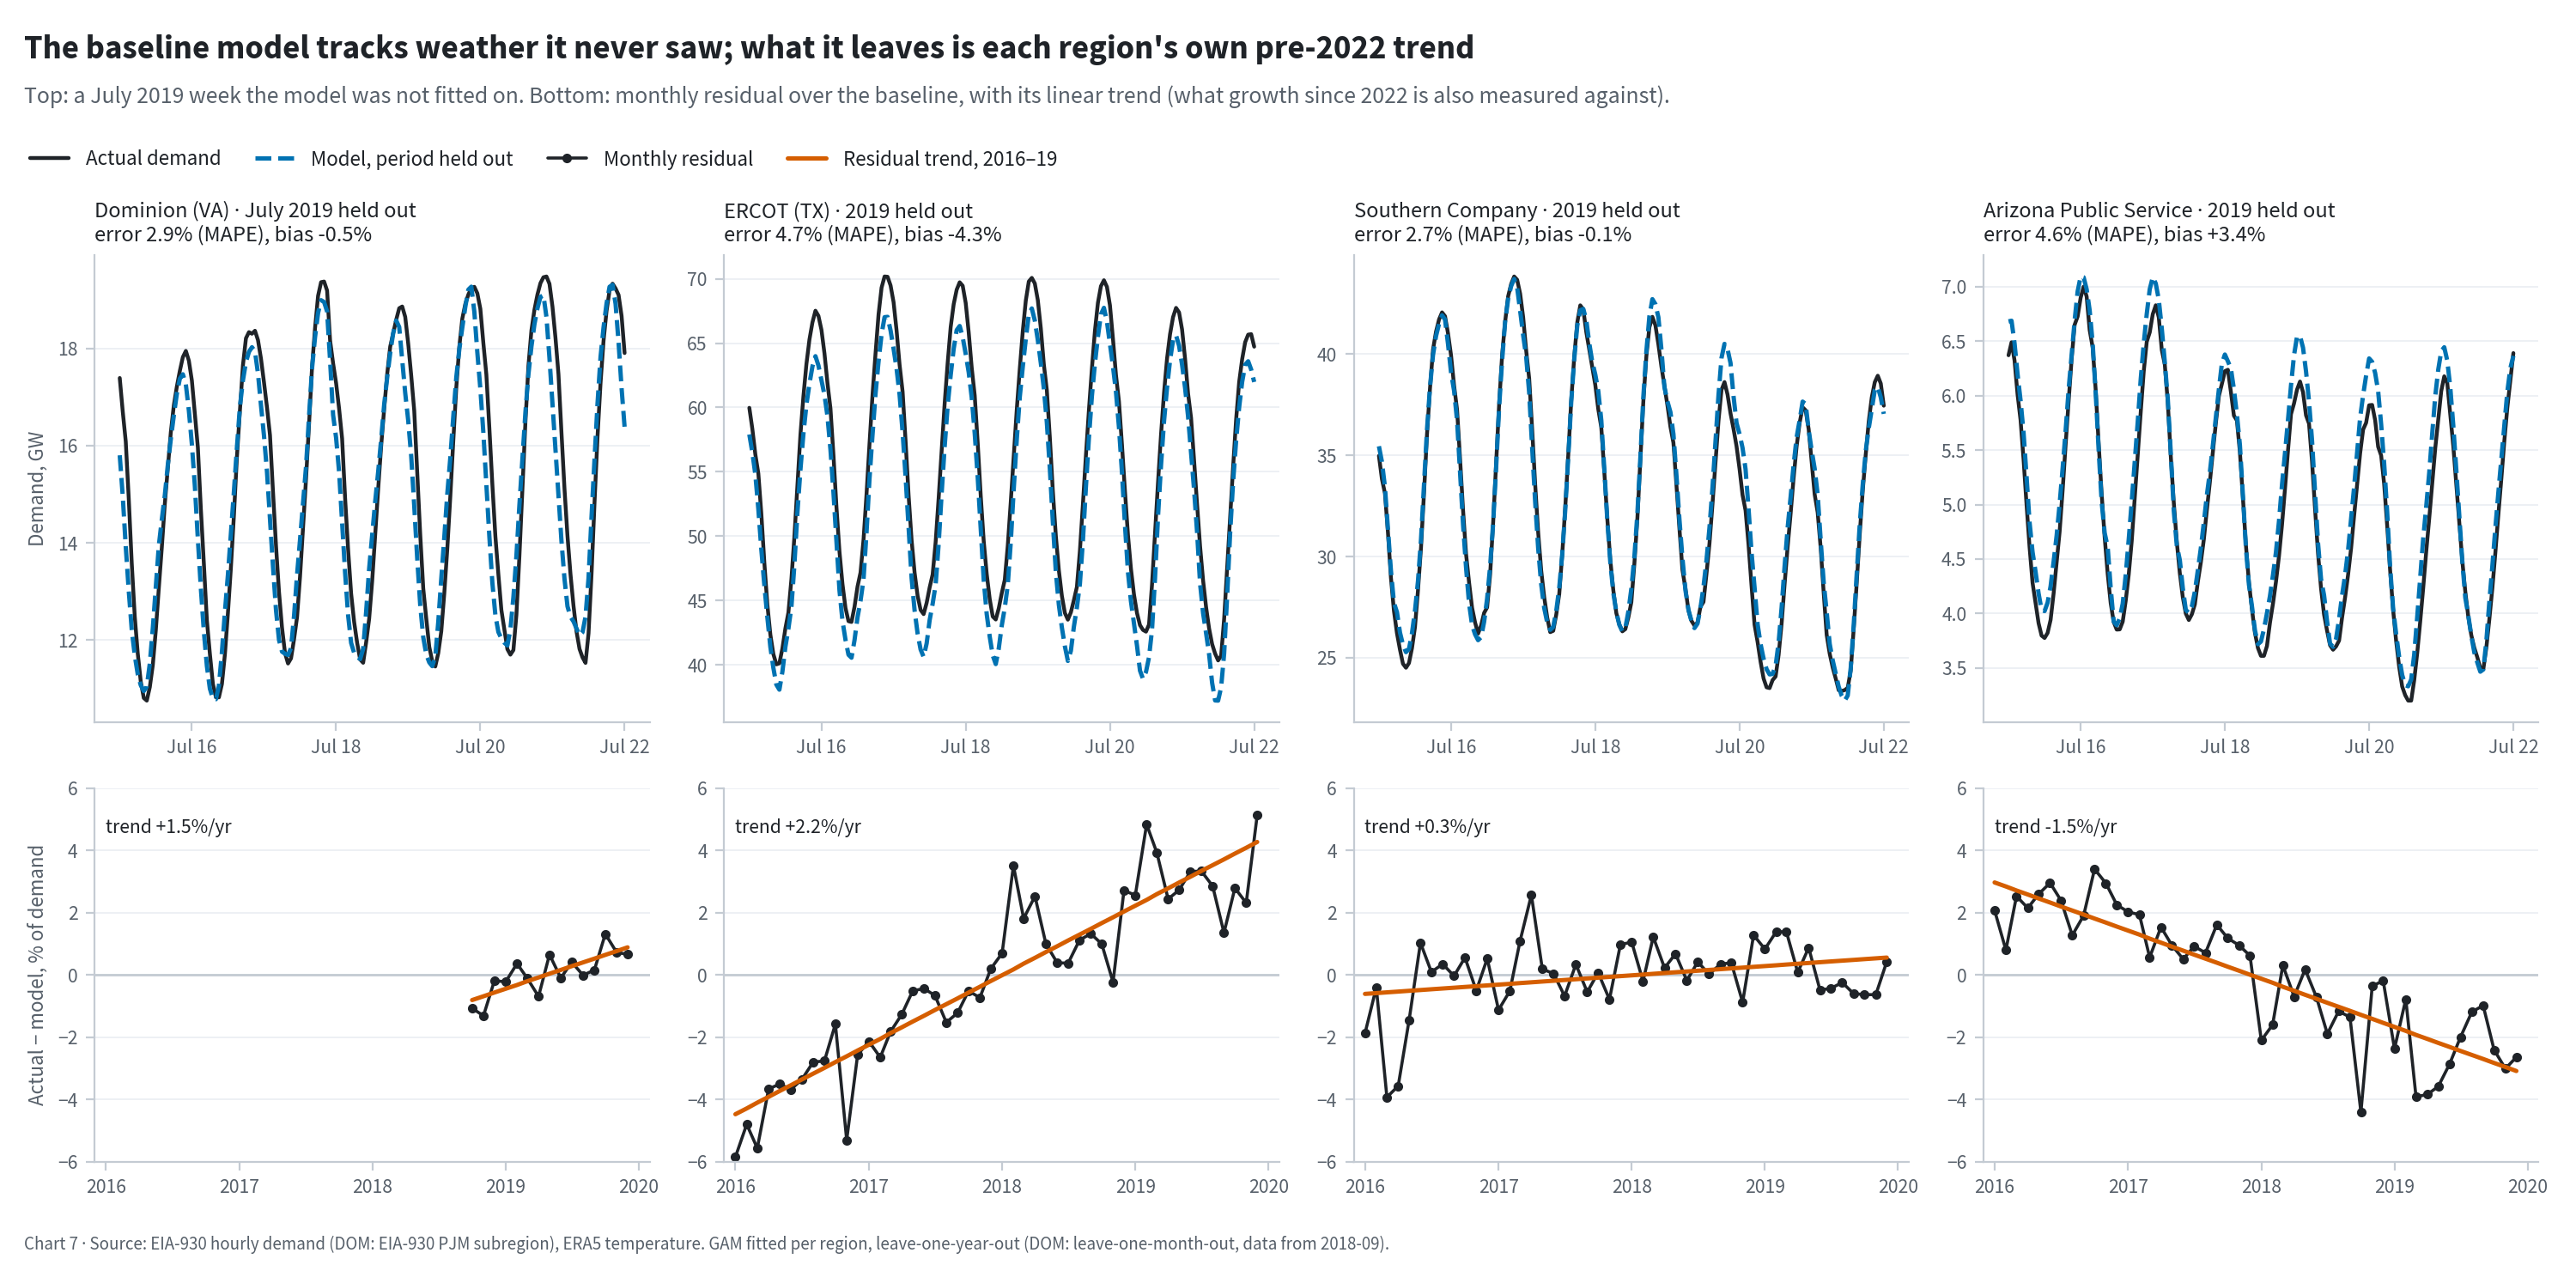

In [5]:
# Final themed figure (Prompt 16): light + dark, PNG + SVG in report/figures/
from IPython.display import Image
from glg.viz import figures as F
F.main(['chart7_validation'])
Image(filename=str(F.FIGURES_DIR / 'chart7_validation.png'), width=900)

## Notes

* GAM beats degree-day OLS on shape MAPE for every BA (pooled 2.0–3.5% vs 2.3–4.1%), so the GAM is the primary model for Prompt 8's comparison.
* **DOPD fails** (shape MAPE 5.3%, residual trend +5%/yr, 2019 bias −13%): the small Douglas County PUD load changed too fast inside the baseline to give a stable counterfactual.
* **Steps inside the baseline:** PSCO +8% from May 2019 (also in FERC 714, so a real change in the BA's load, not EIA error); LGEE about −5% from April 2019 (partly EIA-930-specific; start of the LGEE break pinned in Prompt 3).
* **Already-growing BAs** (residual trend > +1%/yr): ERCO, GCPD, PACE, PSCO, DOM, NEVP, SRP, SWPP. **Shrinking**: CISO, ISNE, AZPS, LGEE (behind-the-meter solar and efficiency are the usual suspects).